In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold





In [4]:
covertype = pd.read_csv("../data/covtype.csv")
covertype.head()


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


Create X y split, confirm that there are only 2 answers in the categories between Soil_Type1 and Soil_Type40

In [5]:
X = covertype.drop('Cover_Type', axis=1)
y = covertype['Cover_Type']

unique_values = X[['Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40']].nunique()
non_unique = [val for val in unique_values if val != 2]
# we make sure that soiltype is one hot, which it is
print(non_unique)

[]


varience threshold 

In [6]:
#first we will do it the "incorrect way" by creating our variance threshold before cross validation. both will have the threshold of < 5%
selector = VarianceThreshold(threshold=0.05)
X_preCV = selector.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_preCV, y, test_size=0.2, random_state=42)



## About your question of collinearity
Collinearity is when 2 or more parameters are highly correlated.
Models that are sensitive to collinearity: linear regression, logistic regression, naive bayes, MLP
Distance based models like KNN, K-Means and SVMs can have distorted metrics by collinearity.

## Wroking on VarianceThreshold and FeatureSelection to reduce feature set and model complexity

In [14]:
corr_matrix = X.corr(method='pearson')
#commented out because there is too much blocking the screen
print(corr_matrix)


                                    Elevation    Aspect     Slope  \
Elevation                            1.000000  0.015735 -0.242697   
Aspect                               0.015735  1.000000  0.078728   
Slope                               -0.242697  0.078728  1.000000   
Horizontal_Distance_To_Hydrology     0.306229  0.017376 -0.010607   
Vertical_Distance_To_Hydrology       0.093306  0.070305  0.274976   
Horizontal_Distance_To_Roadways      0.365559  0.025121 -0.215914   
Hillshade_9am                        0.112179 -0.579273 -0.327199   
Hillshade_Noon                       0.205887  0.336103 -0.526911   
Hillshade_3pm                        0.059148  0.646944 -0.175854   
Horizontal_Distance_To_Fire_Points   0.148022 -0.109172 -0.185662   
Wilderness_Area1                     0.131838 -0.140123 -0.234576   
Wilderness_Area2                     0.238164  0.055988 -0.036253   
Wilderness_Area3                     0.066550  0.074904  0.125663   
Wilderness_Area4                  

vibe code a system to find worst correlating parameters

Found 5 correlated pairs:
                         Feature_1                         Feature_2  \
76                Wilderness_Area3                  Wilderness_Area1   
34                   Hillshade_3pm                     Hillshade_9am   
29                   Hillshade_3pm                            Aspect   
78                Wilderness_Area4                         Elevation   
9   Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Hydrology   

    Correlation  
76    -0.793593  
34    -0.780296  
29     0.646944  
78    -0.619374  
9      0.606236  


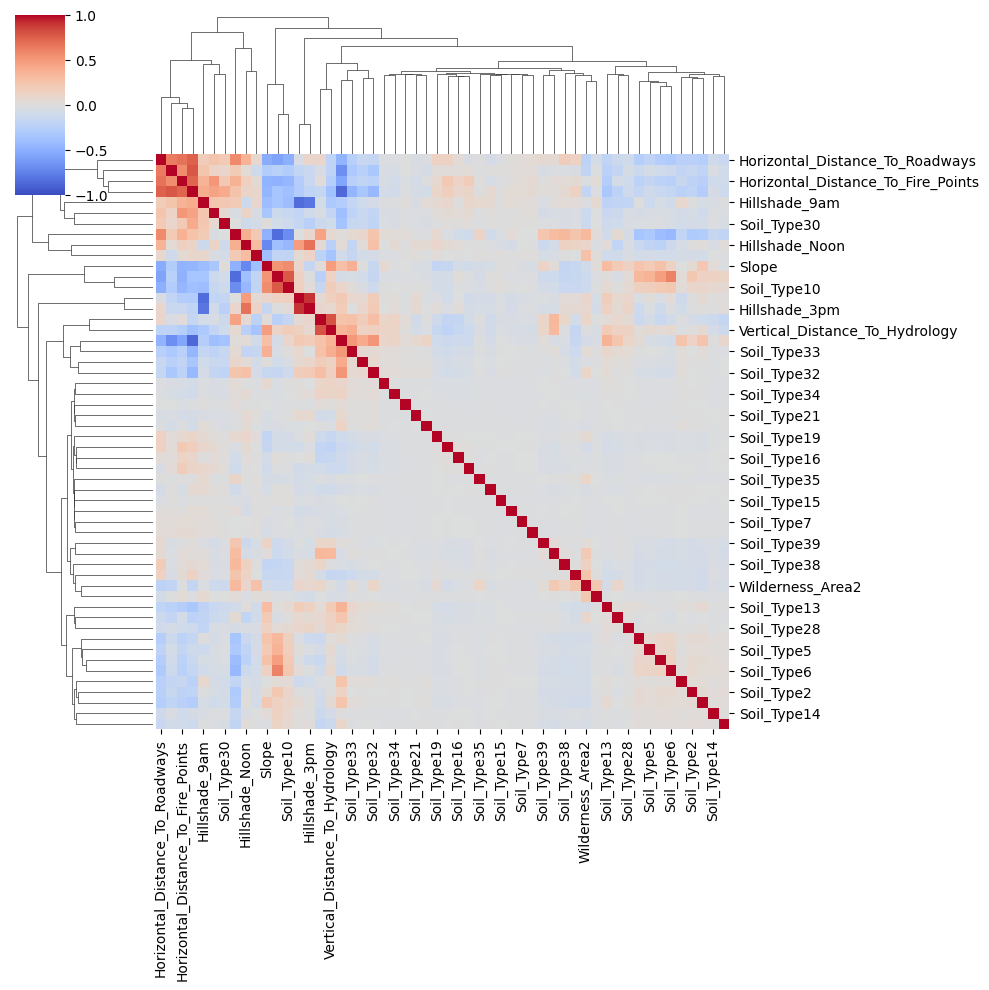

                              Feature_1                       Feature_2  \
59                               Aspect                   Hillshade_3pm   
486                    Wilderness_Area1                Wilderness_Area3   
12                            Elevation                Wilderness_Area4   
57                               Aspect                   Hillshade_9am   
304                       Hillshade_9am                   Hillshade_3pm   
156    Horizontal_Distance_To_Hydrology  Vertical_Distance_To_Hydrology   
516                    Wilderness_Area1                     Soil_Type29   
620                    Wilderness_Area4                     Soil_Type10   
259     Horizontal_Distance_To_Roadways                Wilderness_Area1   
441  Horizontal_Distance_To_Fire_Points                Wilderness_Area1   

     Correlation  
59      0.899490  
486    -0.871406  
12     -0.850264  
57     -0.847871  
304    -0.807038  
156     0.803578  
516     0.789005  
620     0.767144  
259

In [21]:
# 2. Mask the upper triangle and diagonal (since A-B is the same as B-A)
import numpy as np
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
reduced_corr = corr_matrix.mask(mask)

# 3. Stack into a 3-column table and filter by threshold (e.g., |r| >= 0.8)
threshold = 0.6
high_corr = (
    reduced_corr.stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature_1', 'level_1': 'Feature_2', 0: 'Correlation'})
    .assign(abs_corr=lambda x: x['Correlation'].abs())
    .query('abs_corr >= @threshold')
    .sort_values(by='abs_corr', ascending=False)
    .drop(columns=['abs_corr'])
)

print(f"Found {len(high_corr)} correlated pairs:")
print(high_corr.head(20)) # Shows the top 20 worst offenders

##couldnt find anything using this previous system so here is a graph attempt
import seaborn as sns
import matplotlib.pyplot as plt

# Clustermap automatically groups correlated parameters together along the axes
sns.clustermap(corr_matrix.corr(), cmap='coolwarm', vmin=-1, vmax=1, figsize=(10, 10))
plt.show()
import numpy as np
import pandas as pd

# 1. Compute absolute correlation matrix
corr = corr_matrix.corr(method='pearson')

# 2. Extract upper triangle (excluding diagonal)
upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# 3. Stack into a clean table and sort by absolute correlation
top_pairs = (
    upper_tri.stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature_1', 'level_1': 'Feature_2', 0: 'Correlation'})
    .assign(abs_corr=lambda x: x['Correlation'].abs())
    .sort_values(by='abs_corr', ascending=False)
    .drop(columns=['abs_corr'])
)

# Print the top 10 most correlated pairs in the entire dataset
print(top_pairs.head(10))

### Ames.csv

In [ ]:
houses = pd.read_csv("../data/ames.csv")
houses.head()


,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,...,Fence,Misc_Feature,Misc_Val,Mo_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price,Longitude,Latitude
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141,31770,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,5,2010,WD,Normal,215000,-93.619754,42.054035
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80,11622,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,6,2010,WD,Normal,105000,-93.619756,42.053014
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81,14267,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,Gar2,12500,6,2010,WD,Normal,172000,-93.619387,42.052659
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93,11160,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,4,2010,WD,Normal,244000,-93.617320,42.051245
4,Two_Story_1946_and_Newer,Residential_Low_Density,74,13830,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,3,2010,WD,Normal,189900,-93.638933,42.060899
